In [2]:
import os, sys

sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath("__file__"))))
from nbafuns import *
from IPython.core.display import HTML

shots_DIR = "../data/ShotLocationData/"
data_DIR = "../data/box/"
img_DIR_P = "../data/images/players/"
fig_DIR = "../figs/shots/"

In [51]:
year = 2024
all_shots = pd.read_parquet(shots_DIR + f"NBA_Shot_Details_{year}" + ".parquet")
all_shots.columns = map(str.lower, all_shots.columns)
all_shots = all_shots.rename(columns={"shot_made_flag":"shot_made"})
all_shots["loc_x"] = all_shots["loc_x"]/10
all_shots["loc_y"] = all_shots["loc_y"]/10
all_shots['fg2'] = np.where(all_shots['shot_type'] == '2PT Field Goal', 1, 0)
all_shots['fg3'] = np.where(all_shots['shot_type'] == '3PT Field Goal', 1, 0)
all_shots["points"] = (2*all_shots['fg2'] + 3*all_shots['fg3'])*all_shots["shot_made"]
# shots = all_shots.loc[all_shots['shot_distance'] <= 32].reset_index(drop=True)
# shots = all_shots.copy()

In [69]:
sts = ["Dunks","Floaters","Layups","Alley Oops","Reverses","Step Backs","Hook Shots","Turnarounds","Bank Shots","Jump Shots","Cuts","Drives","Finger Rolls","Pullups","Fadeaways","Tips"]
sts_st = ["Dunk","Floating","Layup","Alley","Reverse","Step Back","Hook","Turnaround","Bank","Jump","Cutting","Driving","Finger Roll","Pullup","Fadeaway","Tip"]
for s,st in zip(sts,sts_st):
    all_shots[s]=all_shots["action_type"].str.contains(st)
    if sts == "Pullup":
        all_shots[s]=all_shots["action_type"].str.contains(st) | all_shots["action_type"].str.contains("Pull-Up")
df = all_shots.query("shot_made == True")
df1 = df.groupby(["player_id","player_name"])[sts].sum().reset_index()
df1["P"]=df1["player_id"].astype(str) 
df1 = df1.rename(columns={"player_name":"Player"})

Dunks


GT(_tbl_data=   index                 Player        P  Shots
0      1  Giannis Antetokounmpo   203507    243
1      2            Rudy Gobert   203497    225
2      3            Jalen Duren  1631105    219
3      4            Evan Mobley  1630596    192
4      5            Ivica Zubac  1627826    177
5      6          Jarrett Allen  1628386    159
6      7          Amen Thompson  1641708    138
7      8             OG Anunoby  1628384    132
8      9         Walker Kessler  1631117    131
9     10            Kel'el Ware  1642276    129, _body=<great_tables._gt_data.Body object at 0x000001A2D0DE1180>, _boxhead=Boxhead([ColInfo(var='index', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='center', column_width=None), ColInfo(var='Player', type=<ColInfoTypeEnum.default: 1>, column_label='Player', column_align='left', column_width=None), ColInfo(var='P', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='center', column_width=None), ColInfo(var='Shots', type=<ColInfoTypeEnum.default: 1>, column_label='Shots', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001A2D4DA1D80>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**NBA Leaderboard 2024-25: Dunks**'), subtitle=None, preheader=None), _stubhead=None, _source_notes=['socials:@sradjoker | source: nba.com/stats'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001A2D0DE3400>, _formats=[<great_tables._gt_data.FormatInfo object at 0x000001A2D0DE05E0>], _substitutions=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='floralwhite'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['Consolas']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value=14), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInfo(scss=True, category='table
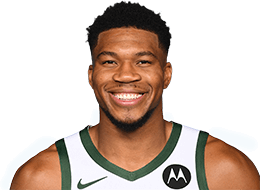
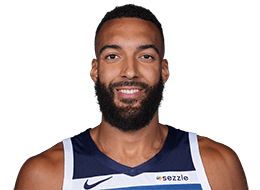
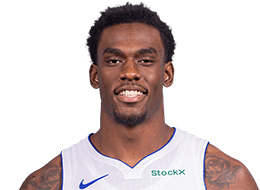
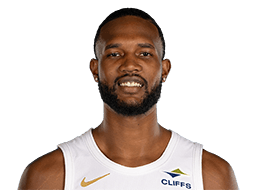
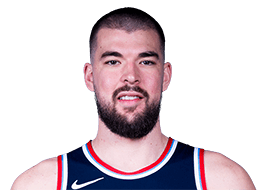
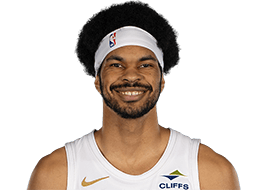
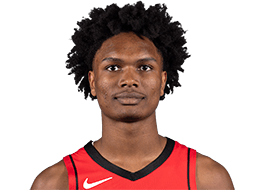
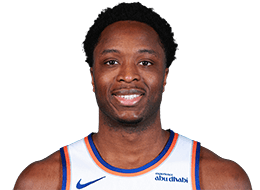
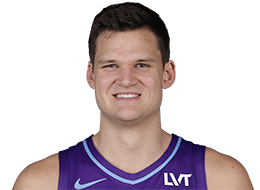
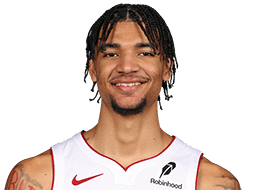

In [70]:
i = 0
st = sts[i]
print(st)
df2 = df1.sort_values(st,ascending=False).head(10).reset_index(drop=True)
df2.index +=1
df2 = df2[["Player","P",st]]
df2.columns = ["Player","P","Shots"]
df2 = df2.reset_index()
t = (
    GT(df2)
    .tab_header(
        title = md(f"**NBA Leaderboard {get_ss(year)}: {sts[i]}**"),
    )
    .tab_source_note(source_note="socials:@sradjoker | source: nba.com/stats")
    .fmt_image(
            columns="P",
            path = img_DIR_P,
            file_pattern="{}.png"
    )
    .cols_label(
        P="",
        index="#",
    )
    .cols_align(align="center")
    .cols_align(align="left", columns="Player")
    .tab_options(
        heading_title_font_size="180%",
        heading_subtitle_font_size="100%",
        # heading_title_font_weight='bold',
        table_background_color="floralwhite",
        column_labels_font_size="120%",
        column_labels_font_weight='bold',
        row_group_font_weight='bold',
        row_group_background_color="#E5E1D8",
        table_font_size=14,
        table_font_names="Consolas", 
        data_row_padding = "0.5px",
        # table_margin_left = 7,
        # table_margin_right = 0,
    )
)
# t.save(fig_DIR + f"NBA_{year}_{st}.png",scale=3,web_driver="firefox")
t

In [71]:
for i in range(len(sts)):
    st = sts[i]
    print(st)
    df2 = df1.sort_values(st,ascending=False).head(10).reset_index(drop=True)
    df2.index +=1
    df2 = df2[["Player","P",st]]
    df2.columns = ["Player","P","Shots"]
    df2 = df2.reset_index()
    t = (
        GT(df2)
        .tab_header(
            title = md(f"**NBA Leaderboard {get_ss(year)}: {sts[i]}**"),
        )
        .tab_source_note(source_note="socials:@sradjoker | source: nba.com/stats")
        .fmt_image(
                columns="P",
                path = img_DIR_P,
                file_pattern="{}.png"
        )
        .cols_label(
            P="",
            index="#",
        )
        .cols_align(align="center")
        .cols_align(align="left", columns="Player")
        .tab_options(
            heading_title_font_size="180%",
            heading_subtitle_font_size="100%",
            # heading_title_font_weight='bold',
            table_background_color="floralwhite",
            column_labels_font_size="120%",
            column_labels_font_weight='bold',
            row_group_font_weight='bold',
            row_group_background_color="#E5E1D8",
            table_font_size=14,
            table_font_names="Consolas", 
            data_row_padding = "0.5px",
            # table_margin_left = 7,
            # table_margin_right = 0,
        )
    )
    t.save(fig_DIR + f"NBA_{year}_{st}.png",scale=3,web_driver="firefox")

Dunks
Floaters
Layups
Alley Oops
Reverses
Step Backs
Hook Shots
Turnarounds
Bank Shots
Jump Shots
Cuts
Drives
Finger Rolls
Pullups
Fadeaways
Tips
